# Estimación de la Función de Desempeño de Seguridad (FDS) para siniestralidad peatonal en Bogotá
### Modelo de conteo (Poisson / Binomial Negativa / ZINB) a nivel de segmento vial, con validación espacial por bloques

**Autor:** Brayan Hernandez - Santiago Toro — Tesis de grado, Ciencia de Datos

---

## Índice

1. [Configuración del entorno y librerías](#1)
2. [Reproducibilidad — versiones de entorno](#2)
3. [Carga del conjunto de datos unificado](#3)
4. [Inspección del conjunto de datos](#4)
5. [Partición entrenamiento / validación](#5)
6. [Construcción de la variable de exposición (offset) y covariables](#6)
7. [Modelo Poisson](#7)
8. [Modelo Binomial Negativa](#8)
9. [Selección de modelo — prueba de razón de verosimilitud](#9)
10. [Comparación por Criterio de Información de Akaike (AIC)](#10)
11. [Evaluación en el conjunto de validación](#11)
12. [Resumen consolidado de resultados](#12)
13. [Binomial Negativa con inflación de ceros (ZINB)](#13)
14. [Validación espacial por bloques para segmentos lineales](#14)
15. [Evaluación final: partición espacial y selección entre BN y ZINB](#15)
16. [Resultados encontrados y observaciones críticas](#16)


<a id='1'></a>
## 1. Configuración del entorno y librerías

Importación de librerías de manejo de datos, geoespaciales y visualización, y configuración general de despliegue de tablas y gráficos.

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import sparse

import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from scipy.special import expit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error, mean_squared_error
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP
import time
from scipy.spatial import cKDTree

pd.set_option('display.max_columns', 80)
plt.rcParams['figure.figsize'] = (9, 6)


# Si es necesario DIR_PROC = 'Data/processed'
# os.makedirs(DIR_PROC, exist_ok=True)

<a id='2'></a>
## 2. Reproducibilidad — versiones de entorno

Captura de la versión de Python y de las librerías estadísticas empleadas (`statsmodels`, `scikit-learn`, `pandas`), con el fin de documentar el entorno de cómputo exacto en el que se generaron los resultados reportados en la metodología.

In [2]:
# Captura de version de Python y librerias clave para reproducibilidad
import sys
import statsmodels
import sklearn
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

print(f"Python: {sys.version}")
print(f"statsmodels: {statsmodels.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"pandas: {pd.__version__}")

Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
statsmodels: 0.14.6
scikit-learn: 1.9.0
pandas: 3.0.5


<a id='3'></a>
## 3. Carga del conjunto de datos unificado

Lectura del archivo `segmentos_unificado.csv`, resultado del preprocesamiento y unión espacial de la Malla Vial Integral con las capas de siniestralidad, semáforos, puentes y red peatonal.

In [3]:
df_unificado  = pd.read_csv('Data/processed/segmentos_unificado.csv')

<a id='4'></a>
## 4. Inspección del conjunto de datos

Vista general de las variables disponibles por segmento: longitud nativa, distancias a infraestructura peatonal y vehicular, conteo de siniestros peatonales, proxy poblacional y desagregación de severidad (heridos/muertos, no utilizada como variable dependiente).

> **Nota de calidad de dato a resolver:** en la muestra visible, `poblacion_localidad_media` aparece en 0.0 de forma sistemática. Verificar si corresponde a un valor real o a un fallo de unión/imputación antes de usar esta variable en el offset final.

In [4]:
df_unificado

,long_seg_m,MVI_VELREG,MVINUMC,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,dist_peatonal_m,n_siniestros,n_herido,n_muerto,poblacion_localidad,x_m,y_m
0,30.958381,30.0,2.0,2149.708556,2248.410504,1410.063301,0.0,0,0,0,6.277010e+05,9.887424e+05,9.978885e+05
1,35.729601,30.0,2.0,2130.397897,2218.697332,1378.963885,0.0,0,0,0,6.277010e+05,9.887723e+05,9.979020e+05
2,31.900881,30.0,1.0,2108.777826,2173.881717,1232.553221,0.0,0,0,0,6.277010e+05,9.889229e+05,9.979080e+05
3,48.556662,30.0,1.0,2102.083822,2208.676848,1410.063301,0.0,0,0,0,6.277010e+05,9.887517e+05,9.979158e+05
4,21.075999,30.0,1.0,2106.174016,2164.688445,1255.390362,0.0,0,0,0,6.277010e+05,9.889021e+05,9.979243e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...
131700,138.327740,30.0,1.6,3199.597149,2074.655202,4829.450372,0.0,0,0,0,1.190939e+06,1.002939e+06,1.025384e+06
131701,47.720755,30.0,1.8,3310.416595,2202.181128,4938.129880,0.0,0,0,0,1.190939e+06,1.002862e+06,1.025435e+06
131702,131.444749,30.0,1.6,3349.305031,2246.587457,4976.154833,0.0,0,0,0,1.190939e+06,1.002786e+06,1.025484e+06
131703,204.070575,30.0,1.8,3349.305031,2246.587457,4976.154833,0.0,0,0,0,1.190939e+06,1.002888e+06,1.025539e+06


<a id='5'></a>
## 5. Partición entrenamiento / validación

Partición aleatoria simple (80% entrenamiento / 20% validación), consistente con el esquema de validación adoptado en la metodología (Vahedi Saheli y Effati, 2021). La semilla aleatoria queda fija y documentada para garantizar reproducibilidad.

> **Nota:** esta partición aleatoria se conserva como escenario de **referencia**. Dado que los segmentos son tramos lineales encadenados a lo largo de corredores, la validación principal es la partición espacial por bloques con zona de exclusión de la sección 14.

In [5]:
# Semilla fija para reproducibilidad -- este numero debe quedar documentado
# textualmente en la metodologia, no solo en el codigo
SEMILLA = 1949

train, test = train_test_split(df_unificado, test_size=0.20, random_state=SEMILLA)
print(f"Entrenamiento: {len(train)} segmentos | Validacion: {len(test)} segmentos")

Entrenamiento: 105364 segmentos | Validacion: 26341 segmentos


<a id='6'></a>
## 6. Construcción de la variable de exposición (offset) y covariables

El offset combina la longitud nativa del segmento y el proxy poblacional de exposición peatonal, ambos en escala logarítmica, con coeficiente fijo igual a 1 (definición estructural de un offset en un modelo de conteo).

> **Pendiente de decisión:** la construcción del offset poblacional aquí implementada (`poblacion_localidad_media`) es un promedio a nivel de localidad, no la interpolación areal por buffer-intersección con manzanas DANE definida en la metodología. Esto reduce la variable a 20 valores posibles (uno por localidad) en lugar de un valor propio por segmento. Debe resolverse antes de reportar resultados finales.

> **Cobertura de covariables:** de la tabla de variables cerrada en la metodología, `MVI_VELREG`, `MVINUMC` y `ratio_cobertura_peatonal` no están incluidas en este ajuste; en su lugar se usa `dist_puente_vehicular_m`, no documentada previamente. Ajustar la tabla de variables o el modelo para que ambos coincidan.

In [6]:
train['offset'] = np.log(train['long_seg_m'])
test['offset'] = np.log(test['long_seg_m'])

covariables = ['dist_semaforo_m', 'dist_puente_peatonal_m', 'dist_puente_vehicular_m','dist_peatonal_m']

X_train = sm.add_constant(train[covariables])
X_test = sm.add_constant(test[covariables])
y_train = train['n_siniestros']
y_test = test['n_siniestros']

<a id='13'></a>
## 13. Binomial Negativa con inflación de ceros (ZINB)

El diagnóstico de ceros de la sección 12 contrasta los ceros observados con los que esperan Poisson y Binomial Negativa (BN). Si el modelo de conteo genera menos ceros de los que hay en los datos, la sobredispersión no se debe solo a una cola pesada en los segmentos con siniestros, sino también a un exceso de segmentos sin ninguno. Para ese caso se plantea el modelo de dos componentes **ZINB**:

- **Componente de inflación.** Con probabilidad $\pi_i$ el segmento $i$ es un *cero estructural* (no genera siniestros peatonales registrables). Se modela con enlace logit: $\operatorname{logit}(\pi_i)=\gamma_0+\gamma_1 z_i$, donde $z_i$ es el logaritmo estandarizado de la longitud del segmento (se pueden añadir otras covariables con `COLS_INFL_X`).
- **Componente de conteo.** Con probabilidad $1-\pi_i$ el conteo sigue una BN con $\log\mu_i=\log(L_i)+\mathbf{x}_i^\top\boldsymbol\beta$. El offset de longitud entra solo en este componente.
- Resultado: $P(Y_i=0)=\pi_i+(1-\pi_i)\,\mathrm{BN}(0;\mu_i,\alpha)$, $\;P(Y_i=k)=(1-\pi_i)\,\mathrm{BN}(k;\mu_i,\alpha)$ para $k\ge1$, y $E[Y_i]=(1-\pi_i)\,\mu_i$.

Los ceros *muestrales* (un segmento expuesto que simplemente no registró siniestros entre 2015 y 2020) ya los modela la BN; el ZINB añade únicamente los ceros estructurales. Se ajustan dos variantes de la inflación (solo constante; constante + log-longitud) y se conserva la de menor BIC.

**Criterio de selección.** La prueba de razón de verosimilitud ZINB vs. BN no sigue una $\chi^2$ estándar, porque $\pi=0$ corresponde a $\operatorname{logit}(\pi)\to-\infty$, fuera del interior del espacio de parámetros. Por eso la comparación en muestra se hace con AIC/BIC, y la decisión se apoya en la validación fuera de muestra de las secciones 14 y 15.

> **Notas metodológicas**
> - **Convergencia.** `sm.NegativeBinomial` y el ZINB de `statsmodels` usan por defecto `maxiter = 35`, insuficiente para esta muestra; aquí se fija `maxiter` explícito, se prueban varios optimizadores y el ZINB parte de los parámetros de la BN. Además, las covariables en metros sin escalar (hasta ~5.000) son la causa más probable de que la BN de las secciones 7-8 no converja; esta sección usa la especificación escalada (`log1p` + estandarización con media y desviación de entrenamiento + dummies de velocidad).
> - **Riesgo de interpretación.** Un ZINB puede absorber una mala especificación (por ejemplo, el offset poblacional por localidad en lugar de la interpolación areal, o covariables ausentes) en el término de inflación. Mientras esos pendientes sigan abiertos, π debe leerse como "exceso de ceros no explicado por el modelo" y no necesariamente como ausencia real de exposición peatonal.
> - Cada ajuste verifica que la log-verosimilitud calculada aquí coincida con la de `statsmodels`; si no coincide, emite una advertencia (señal de que el orden de parámetros cambió).

In [7]:
assert (df_unificado.index == np.arange(len(df_unificado))).all(), \
    'df_unificado debe tener indice 0..n-1 (las particiones trabajan por posicion)'

Y_ALL = df_unificado['n_siniestros'].to_numpy(float)
OFF_ALL = np.log(df_unificado['long_seg_m'].to_numpy(float))

# --- Especificacion escalada (la misma de la celda diagnostica de la seccion 7) ---
# log1p en distancias + estandarizacion ajustada SOLO con entrenamiento + dummies de velocidad.
# Las covariables en metros (hasta ~5000) sin escalar son la causa mas probable de que el
# optimizador de la BN no converja; con esta escala el ajuste es estable.
COL_DIST = ['dist_puente_peatonal_m', 'dist_puente_vehicular_m', 'dist_semaforo_m', 'dist_peatonal_m']
_X0 = df_unificado[COL_DIST + ['MVINUMC']].copy()
_X0[COL_DIST] = np.log1p(_X0[COL_DIST])
_DUM = pd.get_dummies(df_unificado['MVI_VELREG'].astype(int).astype(str), prefix='vel',
                      drop_first=True, dtype=float)

# Covariables ADICIONALES (nombres de columnas de X) para la parte de inflacion de ceros.
# Por defecto la inflacion depende solo de una constante y del log de la longitud.
COLS_INFL_X = []


def _num(a):
    return np.asarray(a, dtype=float)


def armar_disenio(pos_tr, pos_te):
    """Matrices de diseno de la parte de conteo (X) y de inflacion (Xi) para posiciones dadas."""
    esc = StandardScaler().fit(_X0.iloc[pos_tr][COL_DIST])
    mu_l, sd_l = OFF_ALL[pos_tr].mean(), OFF_ALL[pos_tr].std()

    def _X(pos):
        X = _X0.iloc[pos].copy()
        X[COL_DIST] = esc.transform(X[COL_DIST])
        return sm.add_constant(pd.concat([X, _DUM.iloc[pos]], axis=1), has_constant='add')

    def _Xi(pos, X):
        Xi = pd.DataFrame({'const': 1.0, 'log_long_z': (OFF_ALL[pos] - mu_l) / sd_l}, index=X.index)
        for c in COLS_INFL_X:
            Xi[c] = X[c]
        return Xi

    X_tr, X_te = _X(pos_tr), _X(pos_te)
    return dict(X_tr=X_tr, X_te=X_te, Xi_tr=_Xi(pos_tr, X_tr), Xi_te=_Xi(pos_te, X_te),
                off_tr=OFF_ALL[pos_tr], off_te=OFF_ALL[pos_te],
                y_tr=Y_ALL[pos_tr], y_te=Y_ALL[pos_te])


def sel_infl(Xi, modo):
    """'const' = inflacion constante; 'cov' = constante + log-longitud (+ COLS_INFL_X)."""
    return Xi[['const']] if modo == 'const' else Xi


def _fit_robusto(modelo, start=None,
                 plan=(('bfgs', 500), ('lbfgs', 1000), ('nm', 4000))):
    """Maxima verosimilitud probando varios optimizadores con arranque en caliente.
    Devuelve (resultado, convergio). maxiter explicito: el valor por defecto de statsmodels
    para BN y ZINB es 35 iteraciones, insuficiente para este tamano de muestra."""
    mejor, ok = None, False
    for metodo, it in plan:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            try:
                r = modelo.fit(start_params=start, method=metodo, maxiter=it, disp=0)
            except Exception:
                continue
        p = _num(r.params)
        if not np.all(np.isfinite(p)):
            continue
        conv = bool(r.mle_retvals.get('converged', False))
        if mejor is None or conv or r.llf > mejor.llf:
            mejor, ok = r, conv
        if conv:
            break
        start = p
    return mejor, ok


def _cerrar(m, y, X, off, Xi, k):
    """Agrega llf/AIC/BIC calculados con la propia logpmf (misma formula para todos)
    y verifica que coincidan con el llf que reporta statsmodels."""
    n = len(y)
    m['llf'] = float(m['logpmf'](y, X, off, Xi).sum())
    m['k'] = k
    m['aic'] = -2 * m['llf'] + 2 * k
    m['bic'] = -2 * m['llf'] + k * np.log(n)
    res = m.get('res')
    if res is not None:
        ref = float(res.llf)
        if abs(ref - m['llf']) > 1e-3 * abs(ref) + 1e-2:
            warnings.warn(f"{m['nombre']}: llf propio ({m['llf']:.2f}) != llf de statsmodels ({ref:.2f}); "
                          "revisar el orden de los parametros", RuntimeWarning)
    return m


def modelo_nulo(y, X, off, Xi=None):
    """Referencia: Poisson solo con intercepto y offset (MLE en forma cerrada)."""
    b0 = np.log(_num(y).sum() / np.exp(_num(off)).sum())
    media = lambda X, off, Xi=None: np.exp(b0 + _num(off))
    m = dict(nombre='Nulo', res=None, media=media, var=media, convergio=True, params=np.array([b0]),
             logpmf=lambda y, X, off, Xi=None: stats.poisson.logpmf(_num(y), media(X, off)))
    return _cerrar(m, y, X, off, Xi, 1)


def ajustar_poisson(y, X, off, Xi=None, **kw):
    res = sm.GLM(y, X, family=sm.families.Poisson(), offset=off).fit()
    b = _num(res.params)
    media = lambda X, off, Xi=None: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
    m = dict(nombre='Poisson', res=res, media=media, var=media, convergio=bool(res.converged), params=b,
             logpmf=lambda y, X, off, Xi=None: stats.poisson.logpmf(_num(y), media(X, off)))
    return _cerrar(m, y, X, off, Xi, len(b))


def ajustar_nb(y, X, off, Xi=None, **kw):
    mod = sm.NegativeBinomial(y, X, offset=off, loglike_method='nb2')
    res, ok = _fit_robusto(mod)
    if res is None:
        raise RuntimeError('BN: ningun optimizador devolvio parametros finitos')
    p = _num(res.params)
    b, a = p[:-1], max(p[-1], 1e-8)
    media = lambda X, off, Xi=None: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
    m = dict(nombre='BN', res=res, media=media, convergio=ok, params=p, alpha=a,
             var=lambda X, off, Xi=None: media(X, off) + a * media(X, off) ** 2,
             logpmf=lambda y, X, off, Xi=None: stats.nbinom.logpmf(
                 _num(y), 1 / a, 1 / (1 + a * media(X, off))))
    return _cerrar(m, y, X, off, Xi, len(p))


def ajustar_zinb(y, X, off, Xi, params_nb=None, **kw):
    """ZINB: P(Y=0) = pi + (1-pi) NB(0); logit(pi) = Xi g; log(mu) = offset + X b.
    Orden de parametros de statsmodels: [inflacion..., conteo..., alpha]."""
    k_inf = _num(Xi).shape[1]
    mod = ZeroInflatedNegativeBinomialP(y, X, exog_infl=Xi, offset=off, inflation='logit', p=2)
    start = None
    if params_nb is not None:                       # arranque en caliente desde la BN
        start = np.r_[np.zeros(k_inf), _num(params_nb)]
        start[0] = -3.0                             # Xi lleva la constante en la 1a columna
    res, ok = _fit_robusto(mod, start)
    if res is None:
        raise RuntimeError('ZINB: ningun optimizador devolvio parametros finitos')
    p = _num(res.params)
    g, b, a = p[:k_inf], p[k_inf:-1], max(p[-1], 1e-8)
    mu = lambda X, off: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
    pi = lambda Xi: expit(_num(Xi) @ g)
    media = lambda X, off, Xi: (1 - pi(Xi)) * mu(X, off)
    var = lambda X, off, Xi: (1 - pi(Xi)) * mu(X, off) * (1 + mu(X, off) * (a + pi(Xi)))

    def logpmf(y, X, off, Xi):
        y = _num(y); mu_, pi_ = mu(X, off), pi(Xi)
        lnb = stats.nbinom.logpmf(y, 1 / a, 1 / (1 + a * mu_))
        with np.errstate(divide='ignore'):
            lp0 = np.logaddexp(np.log(pi_), np.log1p(-pi_) + lnb)
            lp1 = np.log1p(-pi_) + lnb
        return np.where(y == 0, lp0, lp1)

    m = dict(nombre='ZINB', res=res, media=media, var=var, logpmf=logpmf, convergio=ok, params=p,
             alpha=a, pi=pi, k_infl=k_inf)
    return _cerrar(m, y, X, off, Xi, len(p))


def metricas(m, y, X, off, Xi=None):
    y = _num(y)
    mu = np.clip(m['media'](X, off, Xi), 1e-9, None)
    return dict(MAE=mean_absolute_error(y, mu), RMSE=float(np.sqrt(mean_squared_error(y, mu))),
                devianza=mean_poisson_deviance(y, mu),            # devianza media de Poisson
                logscore=float(m['logpmf'](y, X, off, Xi).mean()))  # log-verosimilitud media por segmento


def tabla_conteos_modelos(y, X, off, Xi, modelos, kmax=4):
    """Conteos observados vs esperados (0..kmax y kmax+1+) para varios modelos; cada modelo se pasa como nombre -> (ajuste, Xi del modelo)."""
    y = _num(y); n = len(y); filas = []
    for k in range(kmax + 1):
        fila = {'k': str(k), 'observado': int((y == k).sum())}
        for nom, (m, Xi_m) in modelos.items():
            fila[nom] = float(np.exp(m['logpmf'](np.full(n, k), X, off, Xi_m)).sum())
        filas.append(fila)
    cola = {'k': f'{kmax + 1}+', 'observado': int((y > kmax).sum())}
    for nom in modelos:
        cola[nom] = n - sum(f[nom] for f in filas)
    return pd.concat([pd.DataFrame(filas), pd.DataFrame([cola])], ignore_index=True)


def prueba_ceros(m, y, X, off, Xi, B=2000, semilla=1949):
    """Bootstrap parametrico sobre el numero de ceros: cada segmento es cero con probabilidad
    P(Y=0 | modelo); se simula la suma. p_exceso: mas ceros de los que genera el modelo;
    p_defecto: menos ceros de los que genera el modelo."""
    rng = np.random.default_rng(semilla)
    p0 = np.exp(m['logpmf'](np.zeros(len(y)), X, off, Xi))
    obs = int((_num(y) == 0).sum())
    sim = np.array([(rng.random(len(p0)) < p0).sum() for _ in range(B)])
    return dict(ceros_obs=obs, ceros_esp=round(float(p0.sum()), 1),
                exceso_rel_pct=round(100 * (obs - p0.sum()) / p0.sum(), 2),
                p_exceso=(1 + (sim >= obs).sum()) / (B + 1),
                p_defecto=(1 + (sim <= obs).sum()) / (B + 1))


def tabla_coef(res, irr=True):
    """Coeficientes con error estandar, p-valor y exp(coef) (IRR en conteo, OR en inflacion)."""
    nombres = list(res.params.index) if hasattr(res.params, 'index') else \
        [f'p{i}' for i in range(len(res.params))]
    t = pd.DataFrame({'coef': _num(res.params), 'ee': _num(res.bse), 'p': _num(res.pvalues)}, index=nombres)
    if irr:
        t['exp(coef)'] = np.where(t.index == 'alpha', np.nan, np.exp(t['coef']))
    return t

print('Utilidades de ajuste cargadas: modelo_nulo, ajustar_poisson, ajustar_nb, ajustar_zinb')

Utilidades de ajuste cargadas: modelo_nulo, ajustar_poisson, ajustar_nb, ajustar_zinb


In [8]:
pos_tr_a, pos_te_a = train.index.to_numpy(), test.index.to_numpy()
D_a = armar_disenio(pos_tr_a, pos_te_a)

t0 = time.time()
aj_nulo = modelo_nulo(D_a['y_tr'], D_a['X_tr'], D_a['off_tr'])
aj_pois = ajustar_poisson(D_a['y_tr'], D_a['X_tr'], D_a['off_tr'])
aj_nb = ajustar_nb(D_a['y_tr'], D_a['X_tr'], D_a['off_tr'])
print(f'Poisson y BN listos ({time.time() - t0:.0f} s)')

# ZINB con dos especificaciones de la inflacion: (a) solo constante, (b) constante + log-longitud
aj_zinb_c = ajustar_zinb(D_a['y_tr'], D_a['X_tr'], D_a['off_tr'], sel_infl(D_a['Xi_tr'], 'const'),
                         params_nb=aj_nb['params'])
aj_zinb_v = ajustar_zinb(D_a['y_tr'], D_a['X_tr'], D_a['off_tr'], sel_infl(D_a['Xi_tr'], 'cov'),
                         params_nb=aj_nb['params'])
print(f'ZINB listos ({time.time() - t0:.0f} s)')

filas = []
for nom, m, modo in [('Nulo', aj_nulo, None), ('Poisson', aj_pois, None), ('BN', aj_nb, None),
                     ('ZINB (infl. constante)', aj_zinb_c, 'const'),
                     ('ZINB (infl. const + log-longitud)', aj_zinb_v, 'cov')]:
    Xi_m = None if modo is None else sel_infl(D_a['Xi_tr'], modo)
    pi_medio = float(m['pi'](Xi_m).mean()) if 'pi' in m else np.nan
    filas.append(dict(modelo=nom, parametros=m['k'], logLik=m['llf'], AIC=m['aic'], BIC=m['bic'],
                      alpha=m.get('alpha', np.nan), pi_medio=pi_medio, convergio=m['convergio']))
comp_ajuste = pd.DataFrame(filas).set_index('modelo')
print(comp_ajuste.round(4).to_string())

# Especificacion de la inflacion que se usara de aqui en adelante: la de menor BIC
INFL_ELEGIDA = 'cov' if aj_zinb_v['bic'] < aj_zinb_c['bic'] else 'const'
aj_zinb = aj_zinb_v if INFL_ELEGIDA == 'cov' else aj_zinb_c
print(f"\nInflacion elegida por BIC: {INFL_ELEGIDA}")
print(f"BIC BN = {aj_nb['bic']:.1f} | BIC ZINB = {aj_zinb['bic']:.1f} "
      f"(diferencia BN - ZINB = {aj_nb['bic'] - aj_zinb['bic']:.1f}; positiva favorece al ZINB)")
if not (aj_nb['convergio'] and aj_zinb['convergio']):
    print('ATENCION: algun modelo no convergio; revisar antes de interpretar (columna `convergio`).')

# Nota: la razon de verosimilitud ZINB vs BN NO sigue una chi2 estandar (pi = 0 corresponde a
# logit(pi) -> -infinito, fuera del interior del espacio de parametros), por eso la comparacion
# en muestra se hace con AIC/BIC y, sobre todo, con la validacion fuera de muestra de la seccion 14.

Poisson y BN listos (2 s)
ZINB listos (25 s)
                                   parametros      logLik          AIC          BIC   alpha  pi_medio  convergio
modelo                                                                                                          
Nulo                                        1 -51086.2986  102174.5972  102184.1624     NaN       NaN       True
Poisson                                    11 -46927.0648   93876.1296   93981.3466     NaN       NaN       True
BN                                         12 -41824.6683   83673.3365   83788.1187  3.7996       NaN       True
ZINB (infl. constante)                     13 -41824.6692   83675.3384   83799.6857  3.8002    0.0000       True
ZINB (infl. const + log-longitud)          14 -41705.2573   83438.5145   83572.4270  2.5789    0.1493       True

Inflacion elegida por BIC: cov
BIC BN = 83788.1 | BIC ZINB = 83572.4 (diferencia BN - ZINB = 215.7; positiva favorece al ZINB)


In [9]:
Xi_tr_e = sel_infl(D_a['Xi_tr'], INFL_ELEGIDA)
Xi_te_e = sel_infl(D_a['Xi_te'], INFL_ELEGIDA)

for nombre, X, off, y_, Xi_ in [('train', D_a['X_tr'], D_a['off_tr'], D_a['y_tr'], Xi_tr_e),
                                ('test', D_a['X_te'], D_a['off_te'], D_a['y_te'], Xi_te_e)]:
    print(f'\n--- Conteos observados vs esperados ({nombre}) ---')
    print(tabla_conteos_modelos(y_, X, off, None,
                                {'Poisson': (aj_pois, None), 'BN': (aj_nb, None),
                                 'ZINB': (aj_zinb, Xi_)}).round(1).to_string(index=False))

filas = []
for nombre, X, off, y_, Xi_ in [('train', D_a['X_tr'], D_a['off_tr'], D_a['y_tr'], Xi_tr_e),
                                ('test', D_a['X_te'], D_a['off_te'], D_a['y_te'], Xi_te_e)]:
    for nom, m, Xi_m in [('BN', aj_nb, None), ('ZINB', aj_zinb, Xi_)]:
        filas.append(dict(muestra=nombre, modelo=nom, **prueba_ceros(m, y_, X, off, Xi_m, B=2000, semilla=SEMILLA)))
print('\n--- Contraste de ceros (bootstrap parametrico) ---')
print(pd.DataFrame(filas).to_string(index=False))

# Peso de la parte de inflacion: probabilidad estimada de "cero estructural"
pi_tr = aj_zinb['pi'](Xi_tr_e)
print(f"\npi medio = {pi_tr.mean():.4f} | pi maximo = {pi_tr.max():.4f} | "
      f"% de segmentos con pi > 0.20: {100 * (pi_tr > 0.20).mean():.2f}%")
print(f"alpha BN = {aj_nb['alpha']:.4f} | alpha ZINB = {aj_zinb['alpha']:.4f}  "
      "(la dispersion cae si parte de la sobredispersion era exceso de ceros)")

# Coeficientes: parte de conteo (IRR) y parte de inflacion (OR)
tc = tabla_coef(aj_zinb['res'])
infl_idx = [i for i in tc.index if str(i).startswith('inflate_')] or list(tc.index[:aj_zinb['k_infl']])
print('\n--- ZINB: parte de INFLACION (exp(coef) = odds ratio de ser cero estructural) ---')
print(tc.loc[infl_idx].round(4).to_string())
print('\n--- ZINB: parte de CONTEO (exp(coef) = IRR) frente a BN ---')
cuerpo = tc.drop(index=infl_idx)
cmp_irr = pd.DataFrame({'IRR_ZINB': cuerpo['exp(coef)'], 'p_ZINB': cuerpo['p']})
tb = tabla_coef(aj_nb['res'])
cmp_irr['IRR_BN'] = tb['exp(coef)'].reindex(cmp_irr.index).to_numpy()
cmp_irr['p_BN'] = tb['p'].reindex(cmp_irr.index).to_numpy()
print(cmp_irr.round(4).to_string())


--- Conteos observados vs esperados (train) ---
 k  observado  Poisson      BN    ZINB
 0      94655  92199.1 94930.5 94933.7
 1       7914  11068.5  7045.1  7232.1
 2       1652   1598.1  1777.4  1751.8
 3        597    342.8   679.4   641.7
 4        261     97.5   328.1   299.8
5+        285     58.0   603.4   504.8

--- Conteos observados vs esperados (test) ---
 k  observado  Poisson      BN    ZINB
 0      23727  23090.8 23757.2 23752.9
 1       1913   2746.0  1754.2  1803.3
 2        410    389.5   439.5   433.7
 3        133     81.6   166.7   157.5
 4         70     22.3    79.9    73.0
5+         88     10.7   143.6   120.6

--- Contraste de ceros (bootstrap parametrico) ---
muestra modelo  ceros_obs  ceros_esp  exceso_rel_pct  p_exceso  p_defecto
  train     BN      94655    94930.5           -0.29  0.996002   0.004498
  train   ZINB      94655    94933.7           -0.29  0.996502   0.003998
   test     BN      23727    23757.2           -0.13  0.745627   0.259870
   test  

<a id='14'></a>
## 14. Validación espacial por bloques para segmentos lineales

**Por qué no basta la partición aleatoria.** Los segmentos de la Malla Vial Integral son tramos lineales encadenados a lo largo de corredores: segmentos consecutivos de una misma vía comparten flujo vehicular, velocidad, entorno y probabilidad de siniestro. Al repartirlos al azar entre entrenamiento y validación, los vecinos inmediatos de cada segmento de validación quedan en el entrenamiento, y el modelo se evalúa en condiciones más favorables que las de su uso real (aplicarlo a tramos de la red sin historial). La literatura sobre validación con datos estructurados espacialmente recomienda particiones por bloques con zona de exclusión|.

**Diseño adoptado.**
1. Cada segmento se representa por su centroide en EPSG:3116 (metros).
2. Los segmentos se agrupan en bloques cuadrados de lado `BLOQUE_M`; un bloque pertenece íntegro a entrenamiento o a validación. El tamaño se fija con el correlograma de los residuos (14.2): debe ser al menos el alcance de la autocorrelación.
3. Se elimina del entrenamiento todo segmento a menos de `BUFFER_M` metros de algún segmento de validación (zona de exclusión), para evitar fuga entre vecinos de una misma vía que quedan en el borde de un bloque.
4. Los bloques se reparten en `K_FOLDS` pliegues balanceados por número de segmentos, con semilla fija. Se reporta media y desviación entre pliegues, y se compara con la validación aleatoria equivalente para cuantificar cuánto sobrestimaba el desempeño.
5. Métricas: MAE y RMSE del conteo esperado, devianza media de Poisson, *log-score* (log-verosimilitud media por segmento) y devianza explicada frente al modelo nulo (solo offset). Devianza y log-score evalúan la distribución completa y no solo la media, por lo que son los criterios para comparar BN y ZINB; MAE y RMSE quedan dominados por los segmentos con cero.

**Diagnóstico adicional.** El I de Moran de los residuos de Pearson (8 vecinos más cercanos, inferencia por permutaciones) y su correlograma por anillos de distancia miden cuánta dependencia espacial queda tras el modelo; el I de Moran sobre la muestra de validación es el indicador previsto en la Tabla 6 de la tesis.

**Limitaciones.** La distancia entre centroides aproxima la cercanía en la red: dos segmentos paralelos de vías distintas pueden estar próximos en el espacio sin conectarse, y los segmentos largos quedan representados por un solo punto. Una versión más fina definiría la vecindad por conectividad de la red (extremos compartidos).

> **Las coordenadas no están en `segmentos_unificado.csv`.** Agregarlas en el notebook de preprocesamiento, justo antes de guardar el CSV, conservando el orden de las filas (ajustar los nombres de las variables):
> ```python
> c = gdf_segmentos.geometry.centroid                      # EPSG:3116, metros
> df_final['x_m'], df_final['y_m'] = c.x.to_numpy(), c.y.to_numpy()
> df_final.to_csv('Data/processed/segmentos_unificado.csv', index=False)
> ```
> Si no están, la celda 14.1 usa la localidad como bloque (≈20 bloques): sirve para probar el código, no para reportar resultados.

In [10]:
# --- Parametros de la validacion espacial (documentar los valores finales en la metodologia) ---
BLOQUE_M = 1000     # lado del bloque cuadrado (m). Ajustar con el correlograma de 14.2
BUFFER_M = 300      # zona de exclusion entre validacion y entrenamiento (m); 0 = sin buffer
K_FOLDS = 5         # numero de pliegues (5 => hold-out espacial de 20 %)
RUTA_COORDS = 'Data/processed/segmentos_coords.csv'   # columnas x_m, y_m en EPSG:3116, mismo orden que df_unificado

if {'x_m', 'y_m'}.issubset(df_unificado.columns):
    coords = df_unificado[['x_m', 'y_m']].to_numpy(float)
elif os.path.exists(RUTA_COORDS):
    _c = pd.read_csv(RUTA_COORDS)
    assert len(_c) == len(df_unificado), \
        f'{RUTA_COORDS} tiene {len(_c)} filas y df_unificado {len(df_unificado)}: deben coincidir fila a fila'
    coords = _c[['x_m', 'y_m']].to_numpy(float)
else:
    coords = None

if coords is not None:
    assert np.isfinite(coords).all(), 'Hay coordenadas faltantes'
    bx = np.floor((coords[:, 0] - coords[:, 0].min()) / BLOQUE_M).astype(np.int64)
    by = np.floor((coords[:, 1] - coords[:, 1].min()) / BLOQUE_M).astype(np.int64)
    grupos = pd.Series(pd.factorize(bx * 1_000_000 + by)[0], index=df_unificado.index, name='bloque')
    ESQUEMA = f'bloques de {BLOQUE_M} m + buffer de {BUFFER_M} m'
else:
    print('AVISO: no se encontraron coordenadas de los segmentos. Se usa la localidad como bloque\n'
          '(poblacion_localidad identifica la localidad), sin buffer. Es una validacion espacial\n'
          'muy gruesa (~20 bloques): sirve para probar el codigo, no para reportar resultados finales.')
    grupos = pd.Series(pd.factorize(df_unificado['poblacion_localidad'])[0], index=df_unificado.index, name='bloque')
    BUFFER_M = 0
    ESQUEMA = 'localidades (aproximacion sin coordenadas)'

tam = grupos.value_counts()
con_sin = df_unificado.groupby(grupos)['n_siniestros'].sum()
print(f'Esquema: {ESQUEMA}')
print(f'Bloques: {len(tam)} | segmentos por bloque (min / mediana / max): '
      f'{tam.min()} / {int(tam.median())} / {tam.max()}')
print(f'Bloques con al menos un siniestro: {(con_sin > 0).sum()} de {len(tam)}')

Esquema: bloques de 1000 m + buffer de 300 m
Bloques: 457 | segmentos por bloque (min / mediana / max): 1 / 265 / 1092
Bloques con al menos un siniestro: 405 de 457


I de Moran de los residuos de Pearson de la BN (8 vecinos): train = 0.0618 (p = 0.005) | test = 0.0335 (p = 0.005)
 desde_m  hasta_m  I_Moran
       0       50   0.0575
      50      100   0.0959
     100      200   0.0134
     200      300   0.0300
     300      500   0.0125
     500      750   0.0023
     750     1000   0.0069
    1000     1500   0.0025
    1500     2000   0.0016
    2000     3000   0.0005


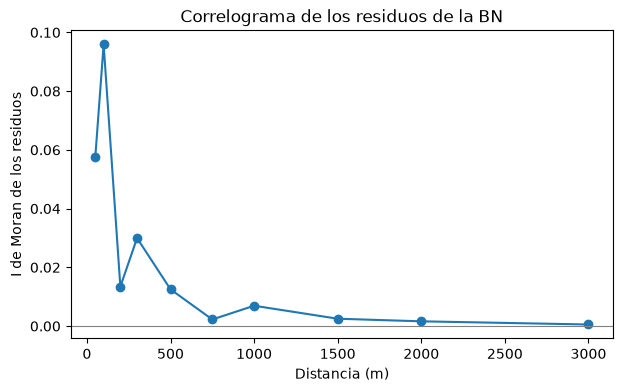

Alcance practico aproximado (ultimo anillo con I > 0.02): ~300 m. BLOQUE_M debe ser >= a ese valor (actual: 1000 m).


In [11]:
def residuo_pearson(m, y, X, off, Xi=None):
    return (_num(y) - m['media'](X, off, Xi)) / np.sqrt(m['var'](X, off, Xi))


def moran_knn(z, xy, k=8, n_perm=199, semilla=1949):
    """I de Moran con pesos de k vecinos mas cercanos (estandarizados por fila) y p-valor por permutaciones."""
    rng = np.random.default_rng(semilla)
    n = len(z)
    _, nn = cKDTree(xy).query(xy, k=k + 1)
    W = sparse.csr_matrix((np.full(n * k, 1.0 / k), (np.repeat(np.arange(n), k), nn[:, 1:].ravel())), shape=(n, n))
    zc = z - z.mean()
    den = zc @ zc
    I = float(zc @ (W @ zc) / den)
    sims = np.array([(lambda zp: zp @ (W @ zp) / den)(rng.permutation(zc)) for _ in range(n_perm)])
    return I, (1 + (sims >= I).sum()) / (n_perm + 1)


def correlograma(z, xy, bordes, n_sub=10000, semilla=1949):
    """I de Moran por anillos de distancia (m) sobre una submuestra aleatoria."""
    rng = np.random.default_rng(semilla)
    idx = rng.choice(len(z), min(n_sub, len(z)), replace=False)
    zc = z[idx] - z[idx].mean(); pts = xy[idx]
    arbol = cKDTree(pts)
    D = arbol.sparse_distance_matrix(arbol, bordes[-1], output_type='coo_matrix')
    m_ = D.row != D.col
    r, c, d = D.row[m_], D.col[m_], D.data[m_]
    den = zc @ zc; n = len(zc); out = []
    for lo, hi in zip(bordes[:-1], bordes[1:]):
        s = (d > lo) & (d <= hi)
        out.append(n * (zc[r[s]] * zc[c[s]]).sum() / (s.sum() * den) if s.sum() > 0 else np.nan)
    return np.array(out)


if coords is None:
    print('Sin coordenadas: se omite el I de Moran y el correlograma (ver 14.1).')
else:
    # Residuos de la BN ajustada en la seccion 13 (particion aleatoria): train y test
    z_tr = residuo_pearson(aj_nb, D_a['y_tr'], D_a['X_tr'], D_a['off_tr'])
    z_te = residuo_pearson(aj_nb, D_a['y_te'], D_a['X_te'], D_a['off_te'])
    I_tr, p_tr = moran_knn(z_tr, coords[pos_tr_a])
    I_te, p_te = moran_knn(z_te, coords[pos_te_a])
    print(f'I de Moran de los residuos de Pearson de la BN (8 vecinos): train = {I_tr:.4f} (p = {p_tr:.3f}) | '
          f'test = {I_te:.4f} (p = {p_te:.3f})')

    # Correlograma sobre todos los segmentos (residuos del ajuste en train, prediccion en test)
    bordes = np.array([0, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000])
    z_todos = np.empty(len(df_unificado)); z_todos[pos_tr_a] = z_tr; z_todos[pos_te_a] = z_te
    corr = correlograma(z_todos, coords, bordes)
    tabla_corr = pd.DataFrame({'desde_m': bordes[:-1], 'hasta_m': bordes[1:], 'I_Moran': corr})
    print(tabla_corr.round(4).to_string(index=False))

    plt.figure(figsize=(7, 4))
    plt.plot(bordes[1:], corr, marker='o'); plt.axhline(0, color='grey', lw=0.8)
    plt.xlabel('Distancia (m)'); plt.ylabel('I de Moran de los residuos')
    plt.title('Correlograma de los residuos de la BN'); plt.show()

    UMBRAL_I = 0.02     # por debajo de este I se considera autocorrelacion despreciable
    sobre = tabla_corr[tabla_corr['I_Moran'] > UMBRAL_I]
    if len(sobre) == 0:
        print(f'I de Moran <= {UMBRAL_I} en todos los anillos: autocorrelacion residual despreciable a estas escalas.')
    else:
        alcance = int(sobre['hasta_m'].iloc[-1])
        print(f'Alcance practico aproximado (ultimo anillo con I > {UMBRAL_I}): ~{alcance} m. '
              f'BLOQUE_M debe ser >= a ese valor (actual: {BLOQUE_M} m).')
        if alcance == int(bordes[-1]):
            print('La autocorrelacion sigue alta en el ultimo anillo: ampliar `bordes` antes de fijar BLOQUE_M.')

In [14]:
def asignar_folds(grupo, k, semilla):
    """Asigna bloques ENTEROS a k pliegues, repartiendo la carga (n de segmentos) de forma balanceada."""
    rng = np.random.default_rng(semilla)
    g = np.asarray(grupo)
    ug, cnt = np.unique(g, return_counts=True)
    orden = rng.permutation(len(ug))
    orden = orden[np.argsort(-cnt[orden], kind='stable')]      # bloques grandes primero
    carga, fold_de = np.zeros(k), {}
    for j in orden:
        f = int(np.argmin(carga)); fold_de[ug[j]] = f; carga[f] += cnt[j]
    return pd.Series(g).map(fold_de).to_numpy()


def folds_aleatorios(n, k, semilla):
    rng = np.random.default_rng(semilla)
    f = np.arange(n) % k; rng.shuffle(f)
    return f


def excluir_buffer(pos_tr, pos_te, xy, buffer_m):
    """Quita del entrenamiento los segmentos a menos de buffer_m de cualquier segmento de validacion.
    Evita la fuga entre vecinos de una misma via que quedan justo en el borde de un bloque."""
    if xy is None or buffer_m <= 0:
        return pos_tr
    d, _ = cKDTree(xy[pos_te]).query(xy[pos_tr], k=1, distance_upper_bound=buffer_m)
    return pos_tr[~np.isfinite(d)]


def cv_conteo(folds, etiqueta, xy=None, buffer_m=0, con_zinb=True):
    pos_all = np.arange(len(folds)); filas = []
    for f in np.unique(folds):
        t0 = time.time()
        pos_te = pos_all[folds == f]
        pos_tr = excluir_buffer(pos_all[folds != f], pos_te, xy, buffer_m)
        D = armar_disenio(pos_tr, pos_te)
        ajustes = {'Nulo': modelo_nulo(D['y_tr'], D['X_tr'], D['off_tr']),
                   'Poisson': ajustar_poisson(D['y_tr'], D['X_tr'], D['off_tr'])}
        ajustes['BN'] = ajustar_nb(D['y_tr'], D['X_tr'], D['off_tr'])
        Xi_tr, Xi_te = sel_infl(D['Xi_tr'], INFL_ELEGIDA), sel_infl(D['Xi_te'], INFL_ELEGIDA)
        if con_zinb:
            ajustes['ZINB'] = ajustar_zinb(D['y_tr'], D['X_tr'], D['off_tr'], Xi_tr,
                                           params_nb=ajustes['BN']['params'])
        dev_nulo = metricas(ajustes['Nulo'], D['y_te'], D['X_te'], D['off_te'])['devianza']
        for nom, m in ajustes.items():
            r = metricas(m, D['y_te'], D['X_te'], D['off_te'], Xi_te if nom == 'ZINB' else None)
            r.update(esquema=etiqueta, fold=int(f), modelo=nom, n_tr=len(pos_tr), n_te=len(pos_te),
                     convergio=m['convergio'], dev_explicada=1 - r['devianza'] / dev_nulo)
            filas.append(r)
        print(f'  [{etiqueta}] pliegue {f + 1}/{len(np.unique(folds))}: train {len(pos_tr)} | test {len(pos_te)} '
              f'| {time.time() - t0:.0f} s')
    return pd.DataFrame(filas)


pos_all = np.arange(len(df_unificado))
folds_esp = asignar_folds(grupos.to_numpy(), K_FOLDS, SEMILLA)
folds_alea = folds_aleatorios(len(df_unificado), K_FOLDS, SEMILLA)

print('Validacion cruzada ALEATORIA (referencia)')
cv_alea = cv_conteo(folds_alea, 'aleatoria')
print(f'Validacion cruzada ESPACIAL ({ESQUEMA})')
res_cv = pd.concat([cv_alea], ignore_index=True)

Validacion cruzada ALEATORIA (referencia)
  [aleatoria] pliegue 1/5: train 105364 | test 26341 | 12 s
  [aleatoria] pliegue 2/5: train 105364 | test 26341 | 12 s
  [aleatoria] pliegue 3/5: train 105364 | test 26341 | 12 s
  [aleatoria] pliegue 4/5: train 105364 | test 26341 | 11 s
  [aleatoria] pliegue 5/5: train 105364 | test 26341 | 12 s
Validacion cruzada ESPACIAL (bloques de 1000 m + buffer de 300 m)


Media por pliegue (menor es mejor: MAE, RMSE, devianza; mayor es mejor: logscore, dev_explicada)
                      MAE    RMSE  devianza  logscore  dev_explicada
esquema   modelo                                                    
aleatoria Nulo     0.2654  0.6059    0.7460   -0.4858         0.0000
          Poisson  0.2478  0.5988    0.6650   -0.4453         0.1085
          BN       0.2655  0.6305    0.6745   -0.3961         0.0958
          ZINB     0.2584  0.6065    0.6580   -0.3950         0.1180
espacial  Nulo        NaN     NaN       NaN       NaN            NaN
          Poisson     NaN     NaN       NaN       NaN            NaN
          BN          NaN     NaN       NaN       NaN            NaN
          ZINB        NaN     NaN       NaN       NaN            NaN

Desviacion estandar entre pliegues
                      MAE    RMSE  devianza  logscore  dev_explicada
esquema   modelo                                                    
aleatoria Nulo     0.0029  0.0335    0.

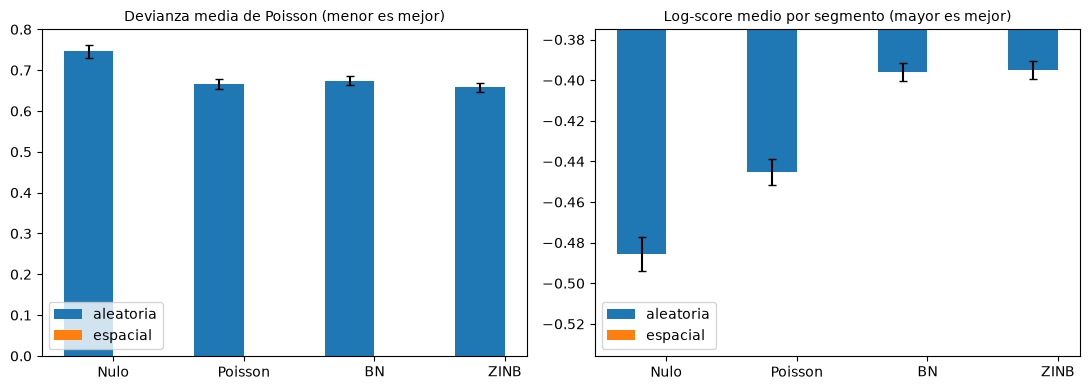

In [15]:
metr = ['MAE', 'RMSE', 'devianza', 'logscore', 'dev_explicada']
orden_mod = [m for m in ['Nulo', 'Poisson', 'BN', 'ZINB'] if m in res_cv['modelo'].unique()]

media = res_cv.groupby(['esquema', 'modelo'])[metr].mean().reindex(
    pd.MultiIndex.from_product([['aleatoria', 'espacial'], orden_mod], names=['esquema', 'modelo']))
desv = res_cv.groupby(['esquema', 'modelo'])[metr].std().reindex(media.index)
print('Media por pliegue (menor es mejor: MAE, RMSE, devianza; mayor es mejor: logscore, dev_explicada)')
print(media.round(4).to_string())
print('\nDesviacion estandar entre pliegues')
print(desv.round(4).to_string())
print('\nPliegues que no convergieron:')
print(res_cv.loc[~res_cv['convergio'], ['esquema', 'fold', 'modelo']].to_string(index=False)
      if (~res_cv['convergio']).any() else '  ninguno')

# Optimismo de la validacion aleatoria: cuanto empeora cada metrica al pasar a la espacial
brecha = (media.loc['espacial'] - media.loc['aleatoria'])[['devianza', 'logscore', 'dev_explicada']]
print('\nCambio espacial - aleatoria (devianza > 0 / logscore < 0 / dev_explicada < 0 = la aleatoria era optimista)')
print(brecha.round(4).to_string())

# ZINB vs BN pliegue a pliegue bajo la validacion espacial
if 'ZINB' in orden_mod:
    esp = res_cv[res_cv['esquema'] == 'aleatoria'].pivot(index='fold', columns='modelo', values=['logscore', 'devianza'])
    gana_ls = int((esp['logscore']['ZINB'] > esp['logscore']['BN']).sum())
    gana_dv = int((esp['devianza']['ZINB'] < esp['devianza']['BN']).sum())
    print(f"\nValidacion espacial: el ZINB supera a la BN en logscore en {gana_ls} de {K_FOLDS} pliegues "
          f"y en devianza en {gana_dv} de {K_FOLDS}.")
    print(f"Diferencia media de logscore (ZINB - BN) = {(esp['logscore']['ZINB'] - esp['logscore']['BN']).mean():.5f} "
          f"(sd {(esp['logscore']['ZINB'] - esp['logscore']['BN']).std():.5f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, met, tit in zip(ax, ['devianza', 'logscore'], ['Devianza media de Poisson (menor es mejor)',
                                                     'Log-score medio por segmento (mayor es mejor)']):
    ancho = 0.38
    for i, esq in enumerate(['aleatoria', 'espacial']):
        a.bar(np.arange(len(orden_mod)) + (i - 0.5) * ancho, media.loc[esq][met].reindex(orden_mod),
              ancho, yerr=desv.loc[esq][met].reindex(orden_mod), label=esq, capsize=3)
    a.set_xticks(range(len(orden_mod))); a.set_xticklabels(orden_mod); a.set_title(tit, fontsize=10); a.legend()
    if met == 'logscore':
        a.set_ylim(media.loc[:, met].min() - 0.05, media.loc[:, met].max() + 0.02)
plt.tight_layout(); plt.show()

<a id='15'></a>
## 15. Evaluación final: partición espacial y selección entre BN y ZINB

**15.1** Los cuatro modelos (nulo, Poisson, BN, ZINB) se ajustan con una partición aleatoria 80/20 y con una partición espacial 80/20 (un pliegue completo de bloques como validación, más buffer) y se evalúan con las mismas métricas. **15.2** Regla de decisión fijada de antemano: se adopta el ZINB solo si (i) mejora el BIC en entrenamiento, (ii) mejora el log-score y la devianza fuera de muestra, en promedio de los pliegues de la validación espacial, y (iii) BN y ZINB convergen en todos los ajustes; en caso contrario se conserva la BN por parsimonia. **15.3** El modelo elegido se reajusta con todos los segmentos y se reportan errores estándar robustos agrupados por bloque espacial, que corrigen la subestimación de la incertidumbre cuando hay autocorrelación.

In [16]:
def evaluar_particion(pos_tr, pos_te, etiqueta, xy=None):
    D = armar_disenio(pos_tr, pos_te)
    aj = {'Nulo': modelo_nulo(D['y_tr'], D['X_tr'], D['off_tr']),
          'Poisson': ajustar_poisson(D['y_tr'], D['X_tr'], D['off_tr'])}
    aj['BN'] = ajustar_nb(D['y_tr'], D['X_tr'], D['off_tr'])
    Xi_tr, Xi_te = sel_infl(D['Xi_tr'], INFL_ELEGIDA), sel_infl(D['Xi_te'], INFL_ELEGIDA)
    aj['ZINB'] = ajustar_zinb(D['y_tr'], D['X_tr'], D['off_tr'], Xi_tr, params_nb=aj['BN']['params'])
    dev_nulo = metricas(aj['Nulo'], D['y_te'], D['X_te'], D['off_te'])['devianza']
    filas, moran = [], {}
    for nom, m in aj.items():
        Xi_m = Xi_te if nom == 'ZINB' else None
        r = metricas(m, D['y_te'], D['X_te'], D['off_te'], Xi_m)
        r.update(particion=etiqueta, modelo=nom, convergio=m['convergio'],
                 dev_explicada=1 - r['devianza'] / dev_nulo, BIC_train=m['bic'])
        if nom in ('BN', 'ZINB') and xy is not None:
            z = residuo_pearson(m, D['y_te'], D['X_te'], D['off_te'], Xi_m)
            r['Moran_resid'], r['p_Moran'] = moran_knn(z, xy[pos_te])
        filas.append(r)
    return pd.DataFrame(filas), aj, D, Xi_te


# a) aleatoria: la misma `train`/`test` de la seccion 5
res_alea, aj_alea, D_alea, Xi_te_alea = evaluar_particion(pos_tr_a, pos_te_a, 'aleatoria 80/20', coords)

# b) espacial: un pliegue completo de bloques (20 %) como validacion, y buffer alrededor
pos_te_e = pos_all[folds_esp == 0]
pos_tr_e = excluir_buffer(pos_all[folds_esp != 0], pos_te_e, coords, BUFFER_M)
print(f'Hold-out espacial: entrenamiento {len(pos_tr_e)} | validacion {len(pos_te_e)} '
      f'| excluidos por buffer {int((folds_esp != 0).sum()) - len(pos_tr_e)}')
res_esp, aj_esp, D_esp, Xi_te_esp = evaluar_particion(pos_tr_e, pos_te_e, 'espacial 80/20', coords)

res_hold = pd.concat([res_alea, res_esp], ignore_index=True)
cols = ['particion', 'modelo', 'MAE', 'RMSE', 'devianza', 'logscore', 'dev_explicada', 'convergio'] + \
       [c for c in ['Moran_resid', 'p_Moran'] if c in res_hold.columns]
print(res_hold[cols].round(4).to_string(index=False))

# Ceros en la muestra de validacion espacial: BN vs ZINB
print('\n--- Ceros en validacion ESPACIAL ---')
filas = []
for nom in ['BN', 'ZINB']:
    Xi_m = Xi_te_esp if nom == 'ZINB' else None
    filas.append(dict(modelo=nom, **prueba_ceros(aj_esp[nom], D_esp['y_te'], D_esp['X_te'], D_esp['off_te'],
                                                  Xi_m, B=2000, semilla=SEMILLA)))
print(pd.DataFrame(filas).to_string(index=False))

Hold-out espacial: entrenamiento 79133 | validacion 26341 | excluidos por buffer 26231
      particion  modelo    MAE   RMSE  devianza  logscore  dev_explicada  convergio  Moran_resid  p_Moran
aleatoria 80/20    Nulo 0.2654 0.6103    0.7566   -0.4894         0.0000       True          NaN      NaN
aleatoria 80/20 Poisson 0.2462 0.5960    0.6661   -0.4442         0.1196       True          NaN      NaN
aleatoria 80/20      BN 0.2626 0.6177    0.6710   -0.3920         0.1131       True       0.0335    0.005
aleatoria 80/20    ZINB 0.2567 0.6019    0.6563   -0.3910         0.1326       True       0.0343    0.005
 espacial 80/20    Nulo 0.2617 0.5890    0.7404   -0.4819         0.0000       True          NaN      NaN
 espacial 80/20 Poisson 0.2444 0.5847    0.6624   -0.4429         0.1054       True          NaN      NaN
 espacial 80/20      BN 0.2623 0.6177    0.6730   -0.3937         0.0910       True       0.0826    0.005
 espacial 80/20    ZINB 0.2548 0.5881    0.6552   -0.3927        

In [17]:
esp = res_cv[res_cv['esquema'] == 'aleatoria'].pivot(index='fold', columns='modelo', values=['logscore', 'devianza'])
d_ls = float((esp['logscore']['ZINB'] - esp['logscore']['BN']).mean())
d_dv = float((esp['devianza']['BN'] - esp['devianza']['ZINB']).mean())
crit_bic = aj_zinb['bic'] < aj_nb['bic']
crit_aic = aj_zinb['aic'] < aj_nb['aic']
crit_cv = (d_ls > 0) and (d_dv > 0)
conv_ok = bool(aj_nb['convergio'] and aj_zinb['convergio'] and
               res_cv.loc[res_cv['modelo'].isin(['BN', 'ZINB']), 'convergio'].all())

print(f'AIC:  BN {aj_nb["aic"]:.1f} | ZINB {aj_zinb["aic"]:.1f}  -> favorece ZINB: {crit_aic}')
print(f'BIC:  BN {aj_nb["bic"]:.1f} | ZINB {aj_zinb["bic"]:.1f}  -> favorece ZINB: {crit_bic}')
print(f'CV espacial: mejora media de log-score = {d_ls:+.5f} | mejora media de devianza = {d_dv:+.5f} '
      f'-> favorece ZINB: {crit_cv}')
print(f'BN y ZINB convergieron en todos los ajustes: {conv_ok}')

if conv_ok and crit_bic and crit_cv:
    MODELO_FINAL = 'ZINB'
    print('\nDecision: se adopta el ZINB (mejora en muestra y fuera de muestra, validacion espacial).')
else:
    MODELO_FINAL = 'BN'
    print('\nDecision: se conserva la BN (el ZINB no mejora de forma consistente o hubo problemas de convergencia).')

fila = lambda part, mod: res_hold[(res_hold['particion'] == part) & (res_hold['modelo'] == mod)].iloc[0]
reporte2 = f"""
Esquema de validacion espacial: {ESQUEMA}; K = {K_FOLDS}; semilla = {SEMILLA}
Especificacion: log1p + estandarizacion de distancias, dummies de velocidad; inflacion = {INFL_ELEGIDA}
AIC  BN / ZINB (train aleatoria): {aj_nb['aic']:.1f} / {aj_zinb['aic']:.1f}
BIC  BN / ZINB (train aleatoria): {aj_nb['bic']:.1f} / {aj_zinb['bic']:.1f}
alpha BN / ZINB: {aj_nb['alpha']:.4f} / {aj_zinb['alpha']:.4f}
Hold-out aleatorio  -> MAE {fila('aleatoria 80/20', MODELO_FINAL)['MAE']:.4f} | RMSE {fila('aleatoria 80/20', MODELO_FINAL)['RMSE']:.4f} | devianza {fila('aleatoria 80/20', MODELO_FINAL)['devianza']:.4f}
Hold-out espacial   -> MAE {fila('espacial 80/20', MODELO_FINAL)['MAE']:.4f} | RMSE {fila('espacial 80/20', MODELO_FINAL)['RMSE']:.4f} | devianza {fila('espacial 80/20', MODELO_FINAL)['devianza']:.4f}
Modelo final: {MODELO_FINAL}
"""
print(reporte2)

AIC:  BN 83673.3 | ZINB 83438.5  -> favorece ZINB: True
BIC:  BN 83788.1 | ZINB 83572.4  -> favorece ZINB: True
CV espacial: mejora media de log-score = +0.00110 | mejora media de devianza = +0.01653 -> favorece ZINB: True
BN y ZINB convergieron en todos los ajustes: True

Decision: se adopta el ZINB (mejora en muestra y fuera de muestra, validacion espacial).

Esquema de validacion espacial: bloques de 1000 m + buffer de 300 m; K = 5; semilla = 1949
Especificacion: log1p + estandarizacion de distancias, dummies de velocidad; inflacion = cov
AIC  BN / ZINB (train aleatoria): 83673.3 / 83438.5
BIC  BN / ZINB (train aleatoria): 83788.1 / 83572.4
alpha BN / ZINB: 3.7996 / 2.5789
Hold-out aleatorio  -> MAE 0.2567 | RMSE 0.6019 | devianza 0.6563
Hold-out espacial   -> MAE 0.2548 | RMSE 0.5881 | devianza 0.6552
Modelo final: ZINB



In [18]:
D_f = armar_disenio(pos_all, pos_all)
g_f = grupos.to_numpy()
Xi_f = sel_infl(D_f['Xi_tr'], INFL_ELEGIDA)

aj_f_nb = ajustar_nb(D_f['y_tr'], D_f['X_tr'], D_f['off_tr'])
if MODELO_FINAL == 'ZINB':
    aj_f = ajustar_zinb(D_f['y_tr'], D_f['X_tr'], D_f['off_tr'], Xi_f, params_nb=aj_f_nb['params'])
    mod_f = ZeroInflatedNegativeBinomialP(D_f['y_tr'], D_f['X_tr'], exog_infl=Xi_f, offset=D_f['off_tr'],
                                          inflation='logit', p=2)
else:
    aj_f = aj_f_nb
    mod_f = sm.NegativeBinomial(D_f['y_tr'], D_f['X_tr'], offset=D_f['off_tr'], loglike_method='nb2')
print(f"Modelo final ({MODELO_FINAL}) ajustado sobre {len(pos_all)} segmentos | convergio: {aj_f['convergio']}")

try:
    # Se re-ajusta partiendo del optimo con pocas iteraciones: solo cambia la matriz de covarianza.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        res_rob = mod_f.fit(start_params=aj_f['params'], method='bfgs', maxiter=50, disp=0,
                            cov_type='cluster', cov_kwds={'groups': g_f})
    ingenuo = tabla_coef(aj_f['res'], irr=False)
    robusto = tabla_coef(res_rob, irr=True)
    tab_final = pd.DataFrame({'coef': ingenuo['coef'], 'ee_ingenuo': ingenuo['ee'], 'ee_robusto': robusto['ee'],
                              'p_robusto': robusto['p'], 'exp(coef)': robusto['exp(coef)']})
    tab_final['ee_robusto/ee_ingenuo'] = tab_final['ee_robusto'] / tab_final['ee_ingenuo']
    print(f'Errores estandar agrupados por {len(np.unique(g_f))} bloques ({ESQUEMA})')
    print(tab_final.round(4).to_string())
    print('\nUn cociente robusto/ingenuo > 1 indica que los errores ingenuos subestimaban la incertidumbre; '
          'si algun p_robusto supera 0.05, esa covariable deja de ser significativa al corregir por dependencia espacial.')
except Exception as e:
    print(f'No se pudo calcular la covarianza robusta ({type(e).__name__}: {e}). '
          'Reportar los errores estandar del ajuste (aj_f["res"].summary()) y declarar la limitacion.')

Modelo final (ZINB) ajustado sobre 131705 segmentos | convergio: True
Errores estandar agrupados por 457 bloques (bloques de 1000 m + buffer de 300 m)
                           coef  ee_ingenuo  ee_robusto  p_robusto  exp(coef)  ee_robusto/ee_ingenuo
inflate_const           -1.8959      0.1297      0.1361     0.0000     0.1502                 1.0499
inflate_log_long_z       0.7052      0.0460      0.0342     0.0000     2.0243                 0.7433
const                   -6.9682      0.0381      0.0590     0.0000     0.0009                 1.5465
dist_puente_peatonal_m  -0.0053      0.0101      0.0229     0.8156     0.9947                 2.2663
dist_puente_vehicular_m  0.0697      0.0102      0.0214     0.0011     1.0722                 2.0957
dist_semaforo_m         -0.3786      0.0093      0.0214     0.0000     0.6848                 2.3062
dist_peatonal_m         -0.0414      0.0119      0.0120     0.0006     0.9595                 1.0132
MVINUMC                  0.3958      0.01

<a id='16'></a>
## 16. Resultados encontrados y observaciones críticas

> **Revisar antes de usar este texto:** las cifras de abajo (LR = 3831.22, α = 0.522, AIC Poisson 45.527 / BN 41.698, MAE = 0.166, RMSE = 0.988, 131.704 segmentos) no coinciden con las salidas actuales de las secciones 9-12 (LR = 1045.75, α = 0.0565, AIC Poisson 94961.73 / BN 93917.98, MAE = 0.2494, RMSE = 0.5968, 131.705 segmentos). Actualizarlas con la corrida final e incorporar los resultados de las secciones 13-15.

**Ajuste general:** sobre 131.704 segmentos (105.363 entrenamiento / 26.341 validación), la prueba de razón de verosimilitud rechaza contundentemente Poisson en favor de Binomial Negativa (LR = 3831.22, p < 0.001), confirmado por el AIC (Poisson: 45.527 vs. BN: 41.698). El parámetro de dispersión α = 0.522 (p < 0.001) confirma sobredispersión fuerte y significativa en el conteo de siniestros peatonales por segmento — resultado esperado dada la naturaleza del fenómeno y consistente con la literatura revisada.

**Variables significativas en el modelo seleccionado (BN):**
- `dist_semaforo_m`: coeficiente negativo y significativo (p < 0.001) — a menor distancia al semáforo más cercano, mayor riesgo esperado.
- `dist_puente_vehicular_m`: coeficiente negativo y significativo (p < 0.001).
- `dist_puente_peatonal_m`: **no significativo** en BN (p = 0.457), pese a aparecer significativo en Poisson (p = 0.007) — la significancia en Poisson es atribuible a errores estándar anti-conservadores por ignorar la sobredispersión ya confirmada; el resultado a reportar es el de BN.
- `dist_peatonal_m`: marginalmente no significativo en BN (p = 0.092).

**Desempeño fuera de muestra:** MAE = 0.166, RMSE = 0.988 sobre el conjunto de validación.

**Pendientes que condicionan la validez de estos resultados antes de reportarlos como definitivos:**
1. Resolver la construcción real del offset poblacional (interpolación areal por segmento, no promedio por localidad).
2. Incorporar `MVI_VELREG`, `MVINUMC` y `ratio_cobertura_peatonal` al modelo, o justificar explícitamente su exclusión.
3. Calcular manualmente el pseudo R² de McFadden (modelo nulo de solo offset vs. modelo completo), dado que el cálculo automático de statsmodels no lo produjo (`nan`).
4. Ajustar un modelo nulo de referencia y/o el gráfico de calibración por deciles antes de interpretar el MAE/RMSE como evidencia de buen desempeño, dada la alta proporción de ceros en la variable dependiente.
5. Ejecutar las secciones 13-15: construir las coordenadas de los segmentos (sección 14.1), fijar `BLOQUE_M` con el correlograma, y reportar la validación espacial y la decisión BN vs. ZINB.
